In [1]:
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from optical_communication_system.components import *
from optical_communication_system.components.utils import normalize_signal
from optical_communication_system.plot import *

2024-08-28 02:02:28.591581: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-28 02:02:28.629579: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-28 02:02:28.629605: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-28 02:02:28.630585: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-08-28 02:02:28.636251: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-28 02:02:28.636651: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [2]:
Component.trace_debug_enabled_by_default = True

data_rate = 1e9
sampling_rate = data_rate * 10
laser_frequency = 193.414e12 # Hz
input_power = 2e-3 # Watts

lpf = ElectricalLowPassFilter(cutoff_frequency=1 * data_rate)

qam4_constellation = IQConstellation(
    bits_per_symbol=2,
    mapping=[
        [-1.0, -1.0], [-1.0, 1.0],
        [ 1.0, -1.0], [ 1.0, 1.0]
    ],
    adjust_for_mzm=True,
    name="qam4_constellation"
)

qam16_constellation = IQConstellation(
    bits_per_symbol=4,
    mapping=[
        [-1.0, -1.0], [-1.0, -0.5], [-1.0, 0.5], [-1.0, 1.0],
        [-0.5, -1.0], [-0.5, -0.5], [-0.5, 0.5], [-0.5, 1.0],
        [ 0.5, -1.0], [ 0.5, -0.5], [ 0.5, 0.5], [ 0.5, 1.0],
        [ 1.0, -1.0], [ 1.0, -0.5], [ 1.0, 0.5], [ 1.0, 1.0]
    ],
    adjust_for_mzm=True,
    name="qam16_constellation"
)

snr = 30.0

constellation = qam16_constellation

system = Composition(components=[
    IQEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        constellation=constellation
    ),  # (ElectricalSignal, ElectricalSignal)
    MapComponent(component=lpf, name="encoder_output"),  # (ElectricalSignal, ElectricalSignal)
    Fork(shape=[2]),  # 2 * ((ElectricalSignal, ElectricalSignal),)
    MapComponents(components=[
        Composition(components=[
            IQModulator(
                carrier_source=Laser(
                    central_frequency=laser_frequency,
                    power=input_power,
                    linewidth=10e9,
                    frequency_count=128),
                name="modulator"
            ),  # OpticalSignal
            OpticalAWGN(power=input_power / 10 ** (snr), name="modulator_output"),  # OpticalSignal
            OpticalFiber(
                attenuation=0.22,
                length=40.0,
                chromatic_dispersion=17.0,
                central_frequency=laser_frequency,
                name="channel"
            ),  # OpticalSignal
            OpticalCoupler1x2()  # (OpticalSignal, OpticalSignal)
        ]),  # (OpticalSignal, OpticalSignal)
        Composition(components=[
            Reindex(indices=(0,)),  # ElectricalSignal
            ExtractTiming(),  # Timing
            Laser(
                central_frequency=laser_frequency,
                power=2e-3,
                linewidth=10e9,
                frequency_count=128
            ),  # OpticalSignal
            OpticalCoupler1x2(),  # (OpticalSignal, OpticalSignal)
            MapComponents(components=[
                OpticalPhaseShifter(phase_shift=math.pi / 2),  # OpticalSignal
                Identity()  # OpticalSignal
            ])  # (OpticalSignal, OpticalSignal)
        ])  # (OpticalSignal, OpticalSignal)
    ]),  # 2 * ((OpticalSignal, OpticalSignal),)
    Reindex(indices=[[(1, 1), (0, 0)], [(0, 1), (1, 0)]]),  # 2 * ((OpticalSignal, OpticalSignal),)
    MapComponent(
        component=Composition(components=[
            OpticalCoupler2x2(flip=True),  # (OpticalSignal, OpticalSignal)
            MapComponent(component=Photodiode()),  # (ElectricalSignal, ElectricalSignal)
            ElectricalSubtractor()  # ElectricalSignal
        ])
    ),  # (ElectricalSignal, ElectricalSignal)
    MapComponent(component=lpf, name="receiver_output"),  # (ElectricalSignal, ElectricalSignal)
    IQDecoder(
        data_rate=data_rate,
        constellation=constellation,
        name="decoder_output"
    ) # tf.TensorSpec(shape=[None], dtype=tf.int32)
]) # tf.TensorSpec(shape=[None], dtype=tf.int32)

rng = tf.random.Generator.from_non_deterministic_state(alg="philox")
ber_tester = BERTester([system])

In [3]:
input_signal = tf.constant([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype=tf.int32)
input_signal = rng.uniform((512,), 0, 2, dtype=tf.int32)

system.trace(input_signal)

Calling Composition(name='composition') with args tf.Tensor(shape=[512], dtype=tf.int32)
|---Calling IQEncoder(name='iq_encoder') with args tf.Tensor(shape=[512], dtype=tf.int32)
|---|---Return tuple[ElectricalSignal, ElectricalSignal]
|---Calling MapComponent(name='encoder_output') with args tuple[ElectricalSignal, ElectricalSignal]
|---|---Calling ElectricalLowPassFilter(name='electrical_low_pass_filter') with args ElectricalSignal
|---|---|---Return ElectricalSignal
|---|---Calling ElectricalLowPassFilter(name='electrical_low_pass_filter') with args ElectricalSignal
|---|---|---Return ElectricalSignal
|---|---Return tuple[ElectricalSignal, ElectricalSignal]
|---Calling Fork(name='fork') with args tuple[ElectricalSignal, ElectricalSignal]
|---|---Return tuple[tuple[ElectricalSignal, ElectricalSignal], tuple[ElectricalSignal, ElectricalSignal]]
|---Calling MapComponents(name='map_components') with args tuple[tuple[ElectricalSignal, ElectricalSignal], tuple[ElectricalSignal, Electrical

<tf.Tensor: shape=(512,), dtype=int32, numpy=
array([0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1,
       0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0,
     

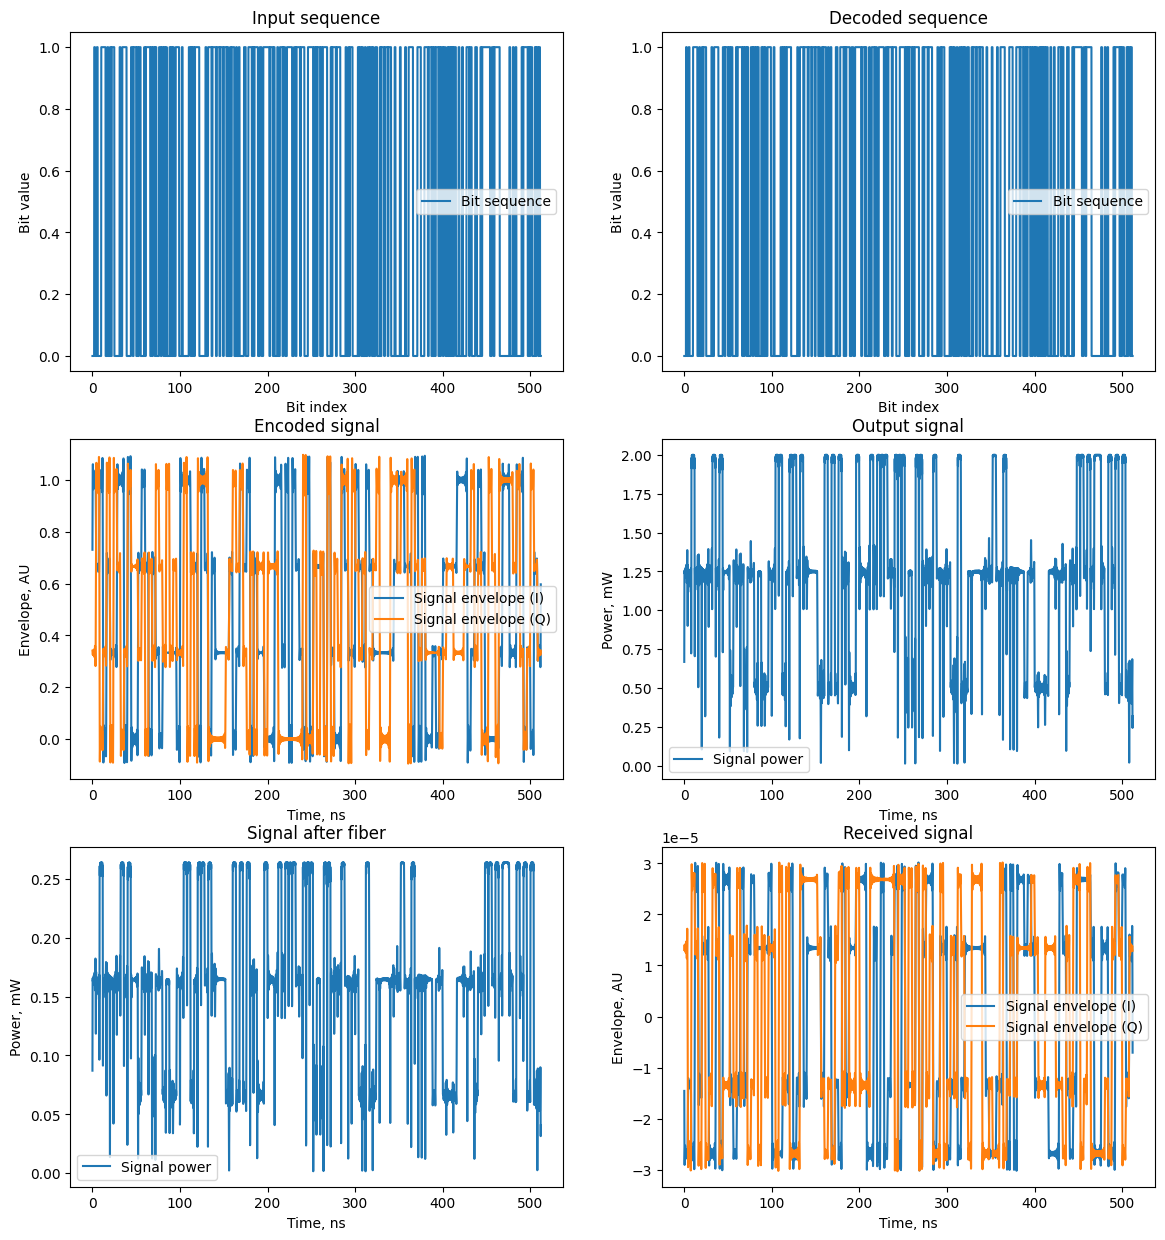

In [4]:
fig, ((input_ax, decoded_ax), (encoded_ax, output_ax), (fiber_ax, received_ax)) = plt.subplots(3, 2)  # type: ignore
fig.set_size_inches(14, 15)

axes = [
    (input_ax, "Input sequence"),
    (encoded_ax, "Encoded signal"),
    (output_ax, "Output signal"),
    (fiber_ax, "Signal after fiber"),
    (received_ax, "Received signal"),
    (decoded_ax, "Decoded sequence")
]

plot_bitseq(input_signal, input_ax)
plot_envelope(system.find_child("encoder_output").output, encoded_ax)
plot_power(system.find_child("modulator_output").output, output_ax)
plot_power(system.find_child("channel").output, fiber_ax)

plot_envelope(system.find_child("receiver_output").output, received_ax)

plot_bitseq(system.output, decoded_ax)

for ax, title in axes:
    ax.set_title(title)
    ax.legend()

In [5]:
%time ber_tester(128, 100)

CPU times: user 11 s, sys: 816 ms, total: 11.8 s
Wall time: 9.85 s


<tf.Tensor: shape=(1,), dtype=float32, numpy=array([0.], dtype=float32)>

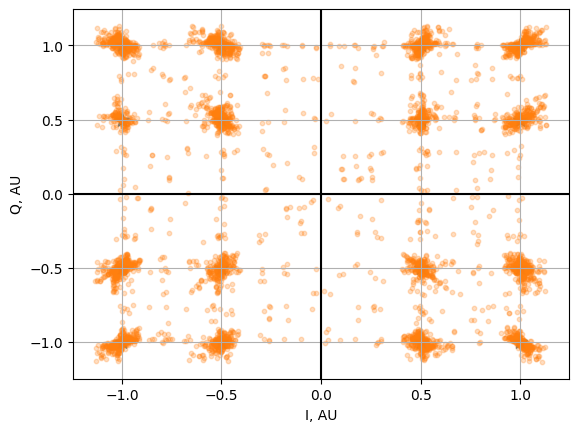

In [6]:
plt.axhline(0.0, color="black")
plt.axvline(0.0, color="black")
plt.grid()
plot_iq_constellation(qam16_constellation, s=100, marker="*")
plot_iq_constellation(system.find_child("receiver_output").output, s=10, iq_units=(3.75e4, "AU"), alpha=0.25)

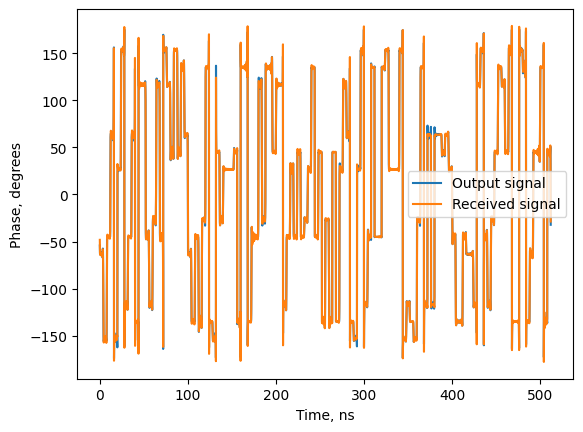

In [7]:
plot_phase(system.find_child("modulator_output").output, label="Output signal")
plot_phase(system.find_child("receiver_output").output, label="Received signal")
plt.legend()

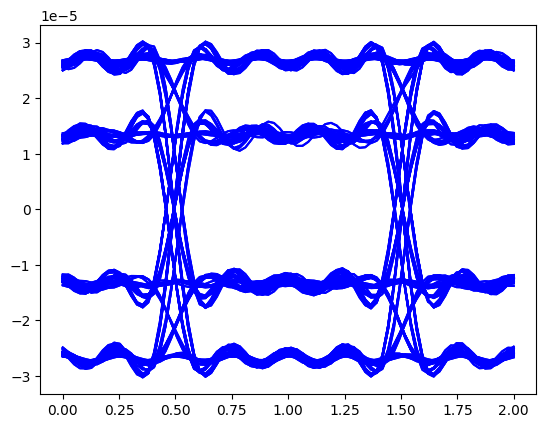

In [8]:
for signal in system.find_child("receiver_output").output:
    plot_eye_diagram(signal, color="blue", alpha=1)
    plot_eye_diagram(signal, color="blue", alpha=1)